# XGBoost model

This notebook uses the fixed train/test split, shared feature list, metrics, and cross-validation folds from `evaluation.py`. Some logistic-regression-only steps are replaced with XGBoost settings that make sense for tree models.

## Shared evaluation setup

We will compare predictions using KL divergence on the full expert vote distributions and macro-F1 against majority-vote labels. The shared helpers in `src/evaluation.py` ensure the same metrics and patient-grouped folds are used across models.

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import ConfusionMatrixDisplay, classification_report
from xgboost import XGBClassifier

# Find the project folder when this notebook is run from either folder.
project_dir = Path.cwd()
if not (project_dir / "HMSdata_prepared").exists():
    project_dir = project_dir.parent
sys.path.insert(0, str(project_dir))

from src.evaluation import (
    CLASS_NAMES,
    RANDOM_STATE,
    cross_validate,
    evaluate,
    get_cv_folds,
    majority_class,
)
from src.models import expand_soft_labels
from src.preprocessing import get_soft_labels, load_selected_features

## Prepare the data

Use the supplied `train_pool` and `test` groups. The split is by patient, so we check that no patient appears in both sets. The other groups are excluded, matching the shared project setup.

In [2]:
data_dir = project_dir / "HMSdata_prepared"
features = pd.read_csv(data_dir / "features.csv")
labels = pd.read_csv(data_dir / "label.csv")
split = pd.read_csv(data_dir / "train_test.csv")[["segment_id", "group"]]

# Join features, expert votes, and the supplied split by segment ID.
data = features.merge(
    labels.drop(columns="patient_id"), on="segment_id", validate="one_to_one"
).merge(split, on="segment_id", validate="one_to_one")

train_data = data[data["group"] == "train_pool"].copy()
test_data = data[data["group"] == "test"].copy()

train_patients = set(train_data["patient_id"])
test_patients = set(test_data["patient_id"])
assert train_patients.isdisjoint(test_patients)

print("Training segments:", len(train_data))
print("Test segments:", len(test_data))
print("No patient appears in both sets:", train_patients.isdisjoint(test_patients))

Training segments: 5569
Test segments: 1155
No patient appears in both sets: True


We use the same selected feature names as the other team models. XGBoost trees do not need feature scaling and can handle missing values, so these feature columns are used directly. Labels are each segment's share of votes for the six classes.

In [3]:
selected_features = load_selected_features()
X_train = train_data[selected_features]
X_test = test_data[selected_features]

y_train = get_soft_labels(train_data)
y_test = get_soft_labels(test_data)
groups = train_data["patient_id"].to_numpy()

print("X:", X_train.shape, X_test.shape)
print("y:", y_train.shape, y_test.shape)
print("labels sum to 1:", np.allclose(y_train.sum(axis=1), 1),
      np.allclose(y_test.sum(axis=1), 1))
print("same features as the team file:", selected_features == load_selected_features())
print("rows line up with labels:",
      np.array_equal(train_data["segment_id"].to_numpy(),
                      data.loc[data["group"] == "train_pool", "segment_id"].to_numpy()))
print("class order:", CLASS_NAMES)

X: (5569, 30) (1155, 30)
y: (5569, 6) (1155, 6)
labels sum to 1: True True
same features as the team file: True
rows line up with labels: True
class order: ['Seizure', 'LPD', 'GPD', 'LRDA', 'GRDA', 'Other']


## Cross-validation folds

All models use the same five folds from `src/evaluation.py`. The table shows the number of majority-vote segments in each class in each validation fold. The held-out test set is not used for cross-validation.

In [4]:
folds = get_cv_folds(y_train, groups)

# Count the majority-vote class in each validation fold.
fold_counts = []
for _, validation_indices in folds:
    classes = majority_class(y_train[validation_indices])
    fold_counts.append(np.bincount(classes, minlength=len(CLASS_NAMES)))

fold_sizes = pd.DataFrame(fold_counts, columns=CLASS_NAMES)
fold_sizes.index.name = "fold"
display(fold_sizes)

# Check that each patient's segments stay together in a fold.
for train_indices, validation_indices in folds:
    train_fold_patients = set(groups[train_indices])
    validation_patients = set(groups[validation_indices])
    assert train_fold_patients.isdisjoint(validation_patients)

print("No patient in both training and validation portions of a fold.")

,Seizure,LPD,GPD,LRDA,GRDA,Other
fold,,,,,,
0,132,212,133,53,70,512
1,133,212,133,53,70,512
2,133,212,133,53,70,512
3,132,213,133,53,70,511
4,133,214,134,53,72,513


No patient in both training and validation portions of a fold.


## Soft labels as weighted rows

XGBoost expects one class per training row. We represent each segment once for every class that received votes, using the vote share as the row's weight. This example shows how the votes for segment 2 are represented. During cross-validation, expansion happens after splitting so copies of a segment cannot leak between folds.

In [5]:
X_expanded, classes, weights = expand_soft_labels(X_train, y_train)
print("segments:", len(X_train), "-> rows:", len(X_expanded))

# Find the weighted rows for the example segment with ID 2.
segment_position = np.flatnonzero(train_data["segment_id"].to_numpy() == 2)[0]
rows_per_segment = (y_train > 0).sum(axis=1)
first_row = rows_per_segment[:segment_position].sum()
last_row = first_row + rows_per_segment[segment_position]
example_rows = slice(first_row, last_row)

example = pd.DataFrame({
    "class": np.array(CLASS_NAMES)[classes[example_rows]],
    "weight": weights[example_rows].round(3),
})
display(example)

# Each segment's weights add up to 1, so segments contribute equally.
print("total weight:", round(weights.sum()), "= number of segments:", len(y_train))

segments: 5569 -> rows: 14015


,class,weight
0,GPD,0.455
1,GRDA,0.091
2,Other,0.455


total weight: 5569 = number of segments: 5569


## Reference models

Before training XGBoost, score two predictions that ignore the features: equal shares for every class and the average vote shares in the training fold. A useful model should improve on these simple references.

In [6]:
def predict_average_votes(X_fit, y_fit, X_eval):
    """Predict the training labels' average vote shares for every row."""
    average_votes = y_fit.mean(axis=0)
    return np.tile(average_votes, (len(X_eval), 1))


def predict_uniform(X_fit, y_fit, X_eval):
    """Predict an equal share for each class."""
    shares = np.full(len(CLASS_NAMES), 1 / len(CLASS_NAMES))
    return np.tile(shares, (len(X_eval), 1))


cv_results = {
    "uniform": cross_validate(predict_uniform, X_train, y_train, folds),
    "average shares": cross_validate(predict_average_votes, X_train, y_train, folds),
}


def summarize(results):
    """Show the mean and standard deviation of each metric across folds."""
    summary = {}
    for name, scores in results.items():
        summary[name] = {
            "kl_mean": scores["kl"].mean(),
            "kl_std": scores["kl"].std(),
            "f1_mean": scores["macro_f1"].mean(),
            "f1_std": scores["macro_f1"].std(),
        }
    return pd.DataFrame(summary).T.round(4)


summarize(cv_results)

,kl_mean,kl_std,f1_mean,f1_std
uniform,1.1712,0.0375,0.0355,0.0001
average shares,0.9358,0.0229,0.1050,0.0001


## Default XGBoost model

This is the first model that uses EEG features. For each fold, we expand the soft labels only after splitting, train XGBoost on that fold's training segments, and score its predictions on the validation segments.

In [7]:
def fit_predict_xgboost(X_fit, y_fit, X_eval, extra_settings=None):
    """Train XGBoost and return class probabilities for the evaluation rows."""
    if extra_settings is None:
        extra_settings = {}

    # Turn each soft label into weighted class rows for this training split.
    X_weighted, y_classes, sample_weights = expand_soft_labels(X_fit, y_fit)

    # These settings make XGBoost predict probabilities for all six classes.
    settings = {
        "objective": "multi:softprob",
        "num_class": len(CLASS_NAMES),
        "eval_metric": "mlogloss",
        "random_state": RANDOM_STATE,
        "n_jobs": -1,
    }
    settings.update(extra_settings)

    model = XGBClassifier(**settings)
    model.fit(X_weighted, y_classes, sample_weight=sample_weights)
    return model.predict_proba(X_eval)


default_scores = cross_validate(
    lambda X, y, X_eval: fit_predict_xgboost(X, y, X_eval),
    X_train,
    y_train,
    folds,
)
cv_results["XGBoost default"] = default_scores

display(default_scores.round(4))
summarize(cv_results)

,fold,kl,macro_f1
0,0,0.4645,0.5076
1,1,0.4283,0.5781
2,2,0.4581,0.5623
3,3,0.4273,0.5080
4,4,0.5255,0.4928


,kl_mean,kl_std,f1_mean,f1_std
uniform,1.1712,0.0375,0.0355,0.0001
average shares,0.9358,0.0229,0.1050,0.0001
XGBoost default,0.4607,0.0399,0.5297,0.0378


## Tune tree depth

`max_depth` controls how many levels each tree can have. We try a few values using the same folds, show the metric table, and plot the average scores with one-standard-error bars. We choose the depth with the lowest average KL.

kl         macro_f1        
             mean     std     mean     std
max_depth                                 
2          0.4432  0.0285   0.5391  0.0303
3          0.4355  0.0277   0.5512  0.0251
4          0.4453  0.0318   0.5388  0.0452
5          0.4490  0.0346   0.5429  0.0440
6          0.4607  0.0399   0.5297  0.0378

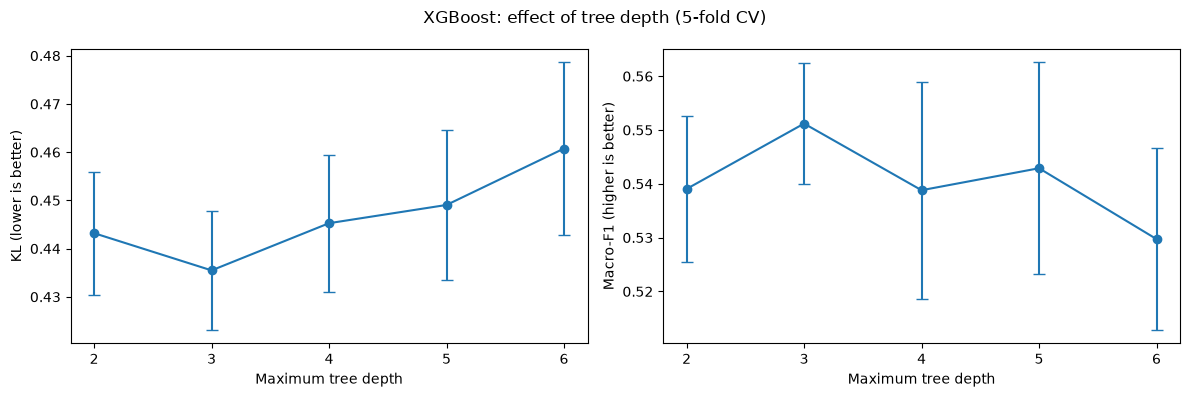

Best max_depth by mean KL: 3


In [8]:
depth_values = [2, 3, 4, 5, 6]
depth_results = []

for depth in depth_values:
    scores = cross_validate(
        lambda X, y, X_eval: fit_predict_xgboost(
            X, y, X_eval, {"max_depth": depth}
        ),
        X_train,
        y_train,
        folds,
    )
    scores["max_depth"] = depth
    depth_results.append(scores)

depth_results = pd.concat(depth_results, ignore_index=True)
depth_summary = depth_results.groupby("max_depth")[["kl", "macro_f1"]].agg(["mean", "std"])
display(depth_summary.round(4))

# Plot both metrics against tree depth.
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
metrics = ["kl", "macro_f1"]
labels = ["KL (lower is better)", "Macro-F1 (higher is better)"]

for ax, metric, label in zip(axes, metrics, labels):
    means = depth_summary[(metric, "mean")]
    standard_errors = depth_summary[(metric, "std")] / np.sqrt(len(folds))
    ax.errorbar(means.index, means, yerr=standard_errors, marker="o", capsize=4)
    ax.set_xlabel("Maximum tree depth")
    ax.set_ylabel(label)
    ax.set_xticks(depth_values)

fig.suptitle("XGBoost: effect of tree depth (5-fold CV)")
plt.tight_layout()
plt.show()

best_depth = int(depth_summary[("kl", "mean")].idxmin())
print("Best max_depth by mean KL:", best_depth)

## Try a refinement

Clipping and L1 regularization are logistic-regression settings, so they do not directly apply here. Instead, we test `min_child_weight`, which controls how readily a tree creates smaller branches. We compare these settings with the depth-tuned model.

In [9]:
child_weight_values = [1, 3, 5]

# This is the depth-tuned model used as the comparison point.
depth_baseline = cross_validate(
    lambda X, y, X_eval: fit_predict_xgboost(
        X, y, X_eval, {"max_depth": best_depth}
    ),
    X_train,
    y_train,
    folds,
)

refinement_results = []
for child_weight in child_weight_values:
    scores = cross_validate(
        lambda X, y, X_eval: fit_predict_xgboost(
            X,
            y,
            X_eval,
            {"max_depth": best_depth, "min_child_weight": child_weight},
        ),
        X_train,
        y_train,
        folds,
    )

    refinement_results.append({
        "min_child_weight": child_weight,
        "kl": scores["kl"].mean(),
        "macro_f1": scores["macro_f1"].mean(),
        "kl_change": (scores["kl"] - depth_baseline["kl"]).mean(),
        "folds_improved": int((scores["kl"] < depth_baseline["kl"]).sum()),
    })

refinement_summary = pd.DataFrame(refinement_results).set_index("min_child_weight")
display(refinement_summary.round(4))

best_child_weight = int(refinement_summary["kl"].idxmin())
print("Best min_child_weight by mean KL:", best_child_weight)

,kl,macro_f1,kl_change,folds_improved
min_child_weight,,,,
1,0.4355,0.5512,0.0000,0
3,0.4368,0.5481,0.0013,2
5,0.4337,0.5605,-0.0018,4


Best min_child_weight by mean KL: 5


The settings selected above are based on cross-validation KL. Now score that final configuration on the same folds and show it next to the reference models and the default XGBoost model. The test set remains untouched until the next section.

In [10]:
final_settings = {
    "max_depth": best_depth,
    "min_child_weight": best_child_weight,
}
final_model_name = (
    f"XGBoost final (depth={best_depth}, "
    f"min_child_weight={best_child_weight})"
)

final_scores = cross_validate(
    lambda X, y, X_eval: fit_predict_xgboost(X, y, X_eval, final_settings),
    X_train,
    y_train,
    folds,
)
cv_results[final_model_name] = final_scores
summarize(cv_results)

,kl_mean,kl_std,f1_mean,f1_std
uniform,1.1712,0.0375,0.0355,0.0001
average shares,0.9358,0.0229,0.1050,0.0001
XGBoost default,0.4607,0.0399,0.5297,0.0378
"XGBoost final (depth=3, min_child_weight=5)",0.4337,0.0304,0.5605,0.0377


## Final evaluation on the test set

Train the selected model on the full training pool and evaluate it once on the held-out test patients. The table reports the two project metrics, followed by a per-class report and a normalized confusion matrix.

,kl,macro_f1,cv_kl
average shares (reference),0.8768,0.1124,0.9358
"XGBoost final (depth=3, min_child_weight=5)",0.4769,0.4892,0.4337


              precision    recall  f1-score   support

     Seizure      0.415     0.562     0.478        48
         LPD      0.619     0.561     0.588       214
         GPD      0.691     0.487     0.571       156
        LRDA      0.273     0.098     0.145        61
        GRDA      0.540     0.307     0.391        88
       Other      0.695     0.844     0.762       588

    accuracy                          0.651      1155
   macro avg      0.539     0.477     0.489      1155
weighted avg      0.634     0.651     0.631      1155



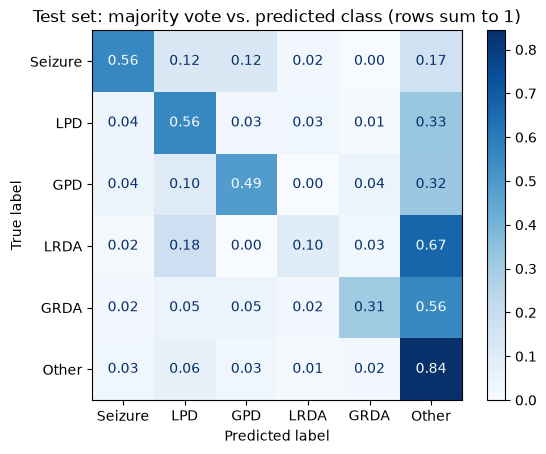

In [11]:
# Train on all training rows and predict probabilities for the test rows.
test_pred = fit_predict_xgboost(X_train, y_train, X_test, final_settings)
reference_pred = predict_average_votes(X_train, y_train, X_test)

test_results = pd.DataFrame({
    "average shares (reference)": evaluate(y_test, reference_pred),
    final_model_name: evaluate(y_test, test_pred),
}).T.astype(float)
test_results["cv_kl"] = [
    cv_results["average shares"]["kl"].mean(),
    cv_results[final_model_name]["kl"].mean(),
]
display(test_results.round(4))

# Compare the predicted class with the experts' majority-vote class.
true_class = majority_class(y_test)
predicted_class = majority_class(test_pred)
print(classification_report(
    true_class,
    predicted_class,
    labels=range(len(CLASS_NAMES)),
    target_names=CLASS_NAMES,
    digits=3,
    zero_division=0,
))

ConfusionMatrixDisplay.from_predictions(
    true_class,
    predicted_class,
    labels=range(len(CLASS_NAMES)),
    display_labels=CLASS_NAMES,
    normalize="true",
    values_format=".2f",
    cmap="Blues",
)
plt.title("Test set: majority vote vs. predicted class (rows sum to 1)")
plt.show()